# Comparison Model 3: Graph Attention Network (GAT) — Journal Retrain

## Prostate Cancer Detection · H&E Histopathology (DiagSet Binary)

**Journal Retrain — structurally identical to Hybrid / LGCN / JGCN retrain notebooks**

- **Local paths**: `<repo>/results\Retrain_GAT\`
- **Graph cache**: `<repo>/cache\gat_graph_cache.pkl`
- **Environment**: `abide` conda env (torch 2.5.1+cu121, PyG 2.8.0, CUDA 12.1)
- **Hardware**: RTX 3060 12 GB

**Architecture (standalone GAT baseline)**
- EfficientNet-B4 (blocks 0–4 frozen, same as LGCN) → 1792 → 512-dim
- GAT: 3 layers × 2 heads on k-NN (k=6) spatial patch graph → 256-dim
- Simple concat fusion (512 + 256 = **768-dim**) → 4-layer MLP head → 2 classes

**Matched protocol vs Hybrid / LGCN / JGCN**
- 80 epochs, patience 15 on val AUC
- Focal Loss (γ=2.0, α=0.75)
- AdamW differential LRs (backbone 1e-4, head 3e-4)
- CosineAnnealingWarmRestarts (T0=10, T_mult=2)
- MixUp α=0.2 (50% of batches), TrivialAugment, RandomErasing p=0.25
- WeightedRandomSampler, TTA×5 at inference (fp32)
- seed=42, image-level 70/15/15 stratified split (identical test set of 901 patches)

**Artefacts produced (Cell 7B)**
- `gat_predictions.npz` — y_true / y_pred / y_prob (non-TTA & TTA) + 768-dim fused features
- `gat_history.json` — full epoch-by-epoch metrics
- `gat_env.json` — reproducibility fingerprint
- `checkpoints_backup/` — local copy of all four artefacts


## CELL 1B — Local PC Setup (RTX 3060 / abide conda env)

In [ ]:
# Resolve the repository root so this notebook runs from a clean clone.
import os
REPO_ROOT = os.getcwd()
while not os.path.exists(os.path.join(REPO_ROOT, 'config.py')):
    parent = os.path.dirname(REPO_ROOT)
    if parent == REPO_ROOT:
        raise RuntimeError('config.py not found - run this notebook from inside the repository')
    REPO_ROOT = parent
print('REPO_ROOT:', REPO_ROOT)


In [1]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 1B — Local PC Setup (RTX 3060 / abide conda env)        ║
# ║   No Drive mount — reads dataset from <repo>\      ║
# ║   Saves ALL retrain artefacts to Journal Ready\Retrain_GAT\  ║
# ╚══════════════════════════════════════════════════════════════╝
import os

WORK_DIR   = os.path.join(REPO_ROOT, 'runs', 'gat')
DATA_ROOT  = REPO_ROOT
DRIVE_ROOT = DATA_ROOT

os.makedirs(WORK_DIR, exist_ok=True)
assert os.path.isdir(WORK_DIR), f'Folder not found: {WORK_DIR}'

print('Work directory  :', WORK_DIR)
print('Files in folder :')
for f in sorted(os.listdir(WORK_DIR)):
    print('  •', f)


Work directory  : <repo>/results\Retrain_GAT
Files in folder :
  • best_gat_model.pth


## CELL 1 — Install Dependencies (skip if abide env already prepared)

In [2]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 1 — Install (SKIP if abide env already has PyG installed)║
# ║   abide env: torch 2.5.1+cu121, PyG 2.8.0 — already ready    ║
# ╚══════════════════════════════════════════════════════════════╝
import torch, sys
print('Python  :', sys.version.split()[0])
print('Torch   :', torch.__version__)
print('CUDA    :', torch.version.cuda)
print('GPU     :', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu')
try:
    import torch_geometric
    print('PyG     :', torch_geometric.__version__, '— OK')
except ImportError:
    print('PyG NOT installed — run the pip cell below')
# !pip install torch_geometric==2.8.0


Python  : 3.11.15
Torch   : 2.6.0+cu124
CUDA    : 12.4
GPU     : NVIDIA GeForce RTX 3060


F:\Anaconda\envs\asd\Lib\site-packages\torch_geometric\__init__.py:4: UserWarning: An issue occurred while importing 'torch-scatter'. Disabling its usage. Stacktrace: [WinError 127] The specified procedure could not be found
  import torch_geometric.typing
F:\Anaconda\envs\asd\Lib\site-packages\torch_geometric\__init__.py:4: UserWarning: An issue occurred while importing 'torch-sparse'. Disabling its usage. Stacktrace: [WinError 127] The specified procedure could not be found
  import torch_geometric.typing
F:\Anaconda\envs\asd\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyG     : 2.8.0 — OK


## CELL 2 — Imports and Config (LOCAL paths)

In [3]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 2 — Imports and Config (LOCAL paths — matches Hybrid)   ║
# ║   Dataset  : <repo>/dataset\{Benign, Malignant}    ║
# ║   Cache    : <repo>/cache\gat_graph_cache.pkl       ║
# ║   Model    : WORK_DIR\best_gat_model.pth                     ║
# ╚══════════════════════════════════════════════════════════════╝
import os, random, warnings, pickle, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm import tqdm
from PIL import Image
import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms as T

from torch_geometric.data import Data, Batch
from torch_geometric.nn import GATConv, global_mean_pool, global_max_pool

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score, confusion_matrix, classification_report,
    matthews_corrcoef, roc_curve, precision_recall_curve, average_precision_score
)
warnings.filterwarnings('ignore')

def denormalize(img_tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std  = np.array([0.229, 0.224, 0.225])
    img  = img_tensor.cpu().numpy().transpose(1, 2, 0)
    return np.clip(img * std + mean, 0, 1)

CONFIG = {
    # ── LOCAL PATHS (matches Hybrid retrain / LGCN retrain / JGCN retrain) ──
    'data_dir'         : os.path.join(REPO_ROOT, 'dataset'),
    'output_dir'       : WORK_DIR,
    'graph_cache_path' : os.path.join(REPO_ROOT, 'cache', 'gat_graph_cache.pkl'),
    'model_save_path'  : os.path.join(WORK_DIR, 'best_gat_model.pth'),

    # ── Image / Graph ──
    'img_size'         : 224,
    'patch_size'       : 32,
    'k_neighbors'      : 6,           # k-NN spatial graph (same as LGCN)

    # ── GAT specific ──
    'gat_hidden_dim'   : 256,
    'gat_heads'        : 2,
    'gat_layers'       : 3,
    'gat_dropout'      : 0.4,
    'fusion_dim'       : 512,
    'num_classes'      : 2,

    # ── Training (IDENTICAL to LGCN / JGCN / Hybrid retrain) ──
    'batch_size'       : 32,
    'num_epochs'       : 80,
    'lr_backbone'      : 1e-4,
    'lr_gat'           : 3e-4,
    'weight_decay'     : 1e-4,
    'patience'         : 15,
    'focal_gamma'      : 2.0,
    'focal_alpha'      : 0.75,
    'seed'             : 42,
    'train_split'      : 0.70,
    'val_split'        : 0.15,
    'test_split'       : 0.15,
    'num_workers'      : 0,
    'use_amp'          : False,
    'tta_n'            : 5,
}
SEED = CONFIG['seed']
MODEL_PATH = CONFIG['model_save_path']

def set_seed(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True

set_seed(SEED)
os.makedirs(CONFIG['output_dir'], exist_ok=True)
os.makedirs(os.path.dirname(CONFIG['graph_cache_path']), exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('=' * 60)
print('  COMPARISON MODEL 3: GRAPH ATTENTION NETWORK (GAT)')
print('  Journal Retrain — matched protocol vs LGCN / JGCN / Hybrid')
print('=' * 60)
print(f'  Device      : {DEVICE}')
if torch.cuda.is_available():
    print(f'  GPU         : {torch.cuda.get_device_name(0)}')
    print(f'  VRAM        : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')
print(f'  Epochs      : {CONFIG["num_epochs"]}  |  Patience : {CONFIG["patience"]}')
print(f'  Batch       : {CONFIG["batch_size"]}')
print(f'  LR backbone : {CONFIG["lr_backbone"]}  |  LR head : {CONFIG["lr_gat"]}')
print(f'  GAT         : {CONFIG["gat_layers"]} layers × {CONFIG["gat_heads"]} heads, dim={CONFIG["gat_hidden_dim"]}')
print(f'  Loss        : Focal (γ={CONFIG["focal_gamma"]}, α={CONFIG["focal_alpha"]})')
print(f'  Scheduler   : CosineAnnealingWarmRestarts (T0=10, T_mult=2)')
print(f'  Cache       : {CONFIG["graph_cache_path"]}')
print(f'  Model out   : {CONFIG["model_save_path"]}')
print('=' * 60)


  COMPARISON MODEL 3: GRAPH ATTENTION NETWORK (GAT)
  Journal Retrain — matched protocol vs LGCN / JGCN / Hybrid
  Device      : cuda
  GPU         : NVIDIA GeForce RTX 3060
  VRAM        : 12.9 GB
  Epochs      : 80  |  Patience : 15
  Batch       : 32
  LR backbone : 0.0001  |  LR head : 0.0003
  GAT         : 3 layers × 2 heads, dim=256
  Loss        : Focal (γ=2.0, α=0.75)
  Scheduler   : CosineAnnealingWarmRestarts (T0=10, T_mult=2)
  Cache       : <repo>/cache\gat_graph_cache.pkl
  Model out   : <repo>/results\Retrain_GAT\best_gat_model.pth


## CELL 3 — k-NN Spatial Graph Construction & Dataset

In [4]:
# ═══════════════════════════════════════════════════════════════════
# CELL 3  k-NN Spatial Graph Construction & Dataset
#
# Graph algorithm: k-NN on patch grid positions (same as LGCN)
# Each patch connects to its k=6 nearest spatial neighbors.
# Unlike Joint Graph, NO cosine similarity filter is applied —
# the graph structure here is purely spatial.
#
# The GAT model then LEARNS which of those spatial neighbors to
# attend to via its multi-head attention weights, rather than
# treating all neighbors equally like GCN does.
# ═══════════════════════════════════════════════════════════════════

from sklearn.neighbors import kneighbors_graph

def build_knn_graph(img_tensor, patch_size=32, k=6):
    """
    Build a k-NN spatial graph over image patches.
    Same graph structure as LGCN — lets GAT vs GCN be the
    only architectural variable in the comparison.

    Node features: 8-dim patch statistics
        [mean, std, max, min, above-mean-ratio, median,
         R-G diff, G-B diff]
    Edges: k=6 nearest spatial neighbors (by patch grid position)
    """
    C, H, W = img_tensor.shape
    ph = pw = patch_size
    n_h = H // ph
    n_w = W // pw

    patches, positions = [], []
    for i in range(n_h):
        for j in range(n_w):
            patch = img_tensor[:, i*ph:(i+1)*ph, j*pw:(j+1)*pw]
            flat  = patch.reshape(-1)
            feat  = torch.stack([
                flat.mean(),
                flat.std(),
                flat.max(),
                flat.min(),
                (flat > flat.mean()).float().mean(),
                flat.median(),
                ((patch[0] - patch[1]).abs()).mean() if C >= 2 else torch.tensor(0.),
                ((patch[1] - patch[2]).abs()).mean() if C >= 3 else torch.tensor(0.),
            ])
            patches.append(feat)
            positions.append([i, j])

    x   = torch.stack(patches)
    pos = np.array(positions, dtype=np.float32)

    A   = kneighbors_graph(pos, n_neighbors=k, mode='connectivity', include_self=False)
    src, dst = A.nonzero()
    edge_index = torch.tensor(np.stack([src, dst], axis=0), dtype=torch.long)
    return Data(x=x, edge_index=edge_index)


#Transforms (identical to LGCN JGCN)
TRAIN_TF = T.Compose([
    T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.3),
    T.RandomRotation(degrees=15),
    T.TrivialAugmentWide(),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.05),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    T.RandomErasing(p=0.25, scale=(0.02, 0.1)),
])
EVAL_TF = T.Compose([
    T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

# TTA transforms (5 views, identical to LGCN  JGCN)
tta_transforms = [
    T.Compose([T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
               T.ToTensor(),
               T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])]),
    T.Compose([T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
               T.RandomHorizontalFlip(p=1.0),
               T.ToTensor(),
               T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])]),
    T.Compose([T.Resize((int(CONFIG['img_size']*1.1), int(CONFIG['img_size']*1.1))),
               T.CenterCrop(CONFIG['img_size']),
               T.ToTensor(),
               T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])]),
    T.Compose([T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
               T.RandomRotation(degrees=(90, 90)),
               T.ToTensor(),
               T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])]),
    T.Compose([T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
               T.RandomRotation(degrees=(180, 180)),
               T.ToTensor(),
               T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])]),
]

#  Dataset class
class ProstateGATDataset(Dataset):
    def __init__(self, file_list, labels, transform):
        self.file_list   = file_list
        self.labels      = labels
        self.transform   = transform
        self.graph_cache = {}
        if os.path.exists(CONFIG['graph_cache_path']):
            with open(CONFIG['graph_cache_path'], 'rb') as f:
                self.graph_cache = pickle.load(f)
            print(f'  Loaded {len(self.graph_cache)} cached graphs')

    def __len__(self): return len(self.file_list)

    def __getitem__(self, idx):
        path  = self.file_list[idx]
        label = self.labels[idx]
        img   = Image.open(path).convert('RGB')
        img_t = self.transform(img)
        if path in self.graph_cache:
            graph = self.graph_cache[path]
        else:
            graph = build_knn_graph(EVAL_TF(img), CONFIG['patch_size'],
                                    CONFIG['k_neighbors'])
            self.graph_cache[path] = graph
        return img_t, graph, torch.tensor(label, dtype=torch.long)


#  MixUp (identical to LGCN / JGCN)
def mixup_data(x, y, alpha=0.2):
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1
    idx = torch.randperm(x.size(0), device=x.device)
    return lam * x + (1 - lam) * x[idx], y, y[idx], lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

def collate_fn(batch):
    imgs, graphs, labels = zip(*batch)
    return torch.stack(imgs), Batch.from_data_list(list(graphs)), torch.stack(labels)

#  Build file lists
data_dir = Path(CONFIG['data_dir'])
IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}
all_paths, all_labels = [], []
for label_idx, cls in enumerate(['Benign', 'Malignant']):
    class_dir = data_dir / cls
    if not class_dir.exists():
        for alt in [cls.capitalize(), cls.upper()]:
            if (data_dir / alt).exists(): class_dir = data_dir / alt; break
    files = [p for p in class_dir.iterdir() if p.suffix.lower() in IMG_EXTS]
    all_paths.extend([str(p) for p in files])
    all_labels.extend([label_idx] * len(files))
    print(f'  {cls:12s}: {len(files):5d} images')
all_paths  = np.array(all_paths)
all_labels = np.array(all_labels)
print(f'  Total: {len(all_paths)} images')

idx_arr = np.arange(len(all_paths))
train_idx, temp_idx = train_test_split(idx_arr, test_size=0.30,
                                        stratify=all_labels, random_state=42)
val_idx, test_idx   = train_test_split(temp_idx, test_size=0.50,
                                        stratify=all_labels[temp_idx], random_state=42)

train_ds = ProstateGATDataset(all_paths[train_idx], all_labels[train_idx], TRAIN_TF)
val_ds   = ProstateGATDataset(all_paths[val_idx],   all_labels[val_idx],   EVAL_TF)
test_ds  = ProstateGATDataset(all_paths[test_idx],  all_labels[test_idx],  EVAL_TF)

# WeightedRandomSampler (identical to LGCN / JGCN)
train_labels_arr = all_labels[train_idx]
class_counts     = np.bincount(train_labels_arr)
sample_weights   = 1.0 / class_counts[train_labels_arr]
sampler = WeightedRandomSampler(sample_weights, len(sample_weights), replacement=True)

train_loader = DataLoader(train_ds, CONFIG['batch_size'], sampler=sampler,
                          num_workers=0, collate_fn=collate_fn, pin_memory=True)
val_loader   = DataLoader(val_ds,   CONFIG['batch_size'], shuffle=False,
                          num_workers=0, collate_fn=collate_fn, pin_memory=True)
test_loader  = DataLoader(test_ds,  CONFIG['batch_size'], shuffle=False,
                          num_workers=0, collate_fn=collate_fn, pin_memory=True)

print(f'  Train:{len(train_idx)} | Val:{len(val_idx)} | Test:{len(test_idx)}')
print(f'  Graph : k-NN spatial (k={CONFIG["k_neighbors"]}), same structure as LGCN')
print(f'  Augmentation: STRONG (TrivialAugment + ColorJitter + RandomErasing)')
print(f'  MixUp : Enabled (alpha=0.2, 50% of batches)')
print(f'  TTA   : {CONFIG["tta_n"]} views at inference')


  Benign      :  3000 images
  Malignant   :  3002 images
  Total: 6002 images
  Loaded 6002 cached graphs
  Loaded 6002 cached graphs
  Loaded 6002 cached graphs
  Train:4201 | Val:900 | Test:901
  Graph : k-NN spatial (k=6), same structure as LGCN
  Augmentation: STRONG (TrivialAugment + ColorJitter + RandomErasing)
  MixUp : Enabled (alpha=0.2, 50% of batches)
  TTA   : 5 views at inference


## CELL 4 — Build k-NN Graph Cache (rebuilds if not present)

In [5]:
# CELL 4  Build k-NN Graph Cache


FORCE_REBUILD = False

if os.path.exists(CONFIG['graph_cache_path']) and not FORCE_REBUILD:
    print('Cache exists. Skipping. Set FORCE_REBUILD=True to rebuild.')
else:
    print(f'Building k-NN graphs for {len(all_paths)} images...')
    graph_cache = {}
    for path in tqdm(all_paths, desc='Building graphs'):
        try:
            img = Image.open(path).convert('RGB')
            graph_cache[path] = build_knn_graph(
                EVAL_TF(img), CONFIG['patch_size'], CONFIG['k_neighbors']
            )
        except:
            pass
    with open(CONFIG['graph_cache_path'], 'wb') as f:
        pickle.dump(graph_cache, f, protocol=4)
    for ds in [train_ds, val_ds, test_ds]:
        ds.graph_cache = graph_cache
    print(f'Done. {len(graph_cache)} graphs cached to: {CONFIG["graph_cache_path"]}')


Cache exists. Skipping. Set FORCE_REBUILD=True to rebuild.


## CELL 5 — GAT Model Architecture

In [6]:
# ═══════════════════════════════════════════════════════════════════
# CELL 5  Graph Attention Network (GAT) Architecture
#
# Image → EfficientNet-B4 → AvgPool → 512-dim          (same as LGCN)
# Graph → Linear Proj → GATConv×3 (multi-head) → Mean+Max Pool → 256-dim
# Fusion → Concat[512 + 256] → MLP → 2 classes
#
# GAT  (this): aggregates with LEARNED attention weights:
#             h_i = sum_j alpha_ij * W*h_j
#             where alpha_ij = softmax(LeakyReLU(a^T [Wh_i || Wh_j]))
#             — the model learns which neighbors matter most
#   This model: GAT alone
#
# Architecture parameters (matched to LGCN where possible):
#   CNN freeze : blocks 0-4  (same as LGCN)
#   GAT dim    : 256 per head × 2 heads → 512 mid-dim, proj to 256
#   GAT layers : 3            (same as LGCN)
#   Dropout    : 0.4          (same as LGCN)
#   Pooling    : mean + max   (same as LGCN)
# ═══════════════════════════════════════════════════════════════════

class GATBranch(nn.Module):
    """
    Multi-head GAT branch.
    Each GATConv layer computes attention-weighted neighbor aggregation.
    Intermediate layers concatenate heads; final layer averages them.
    """
    def __init__(self, node_feat_dim=8, hidden_dim=256,
                 num_heads=2, K=3, dropout=0.4):
        super().__init__()

        # Project raw 8-dim node features to hidden_dim
        self.input_proj = nn.Sequential(
            nn.Linear(node_feat_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ELU(),
        )

        self.convs    = nn.ModuleList()
        self.bns      = nn.ModuleList()
        self.dropout  = nn.Dropout(dropout)

        # Layers 0 .. K-2: multi-head concat → output dim = hidden_dim * num_heads
        for _ in range(K - 1):
            self.convs.append(
                GATConv(
                    in_channels  = hidden_dim,
                    out_channels = hidden_dim,
                    heads        = num_heads,
                    dropout      = dropout,
                    concat       = True,     # concat heads → hidden_dim * num_heads
                    add_self_loops = True,
                )
            )
            self.bns.append(nn.BatchNorm1d(hidden_dim * num_heads))
            hidden_dim = hidden_dim * num_heads   # update for next layer input

        # Final layer: average heads → output dim = out_channels (fixed to 256)
        final_out = 256
        self.convs.append(
            GATConv(
                in_channels  = hidden_dim,
                out_channels = final_out,
                heads        = num_heads,
                dropout      = dropout,
                concat       = False,    # average heads → final_out dim
                add_self_loops = True,
            )
        )
        self.bns.append(nn.BatchNorm1d(final_out))

        # mean + max pooling → 2 * final_out → project to final_out
        self.pool_proj = nn.Sequential(
            nn.Linear(final_out * 2, final_out),
            nn.BatchNorm1d(final_out),
            nn.ELU(),
            nn.Dropout(dropout),
        )
        self.out_dim = final_out

    def forward(self, x, edge_index, batch):
        x = self.input_proj(x)
        for conv, bn in zip(self.convs, self.bns):
            # GAT applies internal dropout on attention coefficients
            x = F.elu(bn(conv(x, edge_index)))
            x = self.dropout(x)
        # Mean + max pooling (same as LGCN)
        g = torch.cat([global_mean_pool(x, batch),
                       global_max_pool(x, batch)], dim=1)
        return self.pool_proj(g)   # (B, 256)


class ProstateGAT(nn.Module):
    def __init__(self, config):
        super().__init__()
        from torchvision.models import efficientnet_b4, EfficientNet_B4_Weights
        backbone = efficientnet_b4(weights=EfficientNet_B4_Weights.IMAGENET1K_V1)
        self.cnn_features = backbone.features
        self.cnn_pool     = nn.AdaptiveAvgPool2d(1)

        # Freeze blocks 0-4 (same as LGCN)
        for i, layer in enumerate(self.cnn_features):
            if i < 5:
                for p in layer.parameters():
                    p.requires_grad = False

        self.cnn_proj = nn.Sequential(
            nn.Linear(1792, config['fusion_dim']),
            nn.BatchNorm1d(config['fusion_dim']),
            nn.SiLU(),
            nn.Dropout(0.3),
        )

        self.gat = GATBranch(
            node_feat_dim = 8,
            hidden_dim    = config['gat_hidden_dim'],
            num_heads     = config['gat_heads'],
            K             = config['gat_layers'],
            dropout       = config['gat_dropout'],
        )

        # fusion_dim (512) + GAT out_dim (256) = 768
        total_dim = config['fusion_dim'] + self.gat.out_dim

        # Same fusion MLP depth as LGCN
        self.fusion_mlp = nn.Sequential(
            nn.Linear(total_dim, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.2),
            nn.Linear(128, config['num_classes']),
        )

        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, img, graph_batch):
        cnn = self.cnn_proj(
            self.cnn_pool(self.cnn_features(img)).flatten(1)
        )
        gat = self.gat(
            graph_batch.x.float(),
            graph_batch.edge_index,
            graph_batch.batch
        )
        return self.fusion_mlp(torch.cat([cnn, gat], dim=1))


model   = ProstateGAT(CONFIG).to(DEVICE)
total_p = sum(p.numel() for p in model.parameters())
train_p = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total params : {total_p:,}')
print(f'Trainable    : {train_p:,}')
gat_out = model.gat.out_dim
print(f'CNN→{CONFIG["fusion_dim"]} | GAT→{gat_out} | Fused→{CONFIG["fusion_dim"]+gat_out}')
print(f'GAT: {CONFIG["gat_layers"]} layers × {CONFIG["gat_heads"]} heads')
print(f'     (concat heads in layers 1-2, average in layer 3)')
print(f'CNN freeze: blocks 0-4 | Fine-tune: blocks 5-8 (same as LGCN)')
print(f'Pooling: mean + max (same as LGCN)')
print()
print('Architecture difference from Hybrid:')
print('  Hybrid  : GAT branch + GCN branch + SE-gated fusion (896-dim concat)')
print('  This    : GAT branch only, simple concat fusion (768-dim)')
print('  Missing : GCN structural signal + learned SE attention gate')


Total params : 20,351,434
Trainable    : 19,022,174
CNN→512 | GAT→256 | Fused→768
GAT: 3 layers × 2 heads
     (concat heads in layers 1-2, average in layer 3)
CNN freeze: blocks 0-4 | Fine-tune: blocks 5-8 (same as LGCN)
Pooling: mean + max (same as LGCN)

Architecture difference from Hybrid:
  Hybrid  : GAT branch + GCN branch + SE-gated fusion (896-dim concat)
  This    : GAT branch only, simple concat fusion (768-dim)
  Missing : GCN structural signal + learned SE attention gate


## CELL 6 — Training Loop (identical protocol, local backup)

In [7]:
# ═══════════════════════════════════════════════════════════════════
# CELL 6  Training Loop (identical protocol to LGCN / JGCN)
# Focal Loss | MixUp | CosineAnnealingWarmRestarts | patience=15
# ═══════════════════════════════════════════════════════════════════

class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, alpha=0.75, reduction='mean'):
        super().__init__()
        self.gamma = gamma; self.alpha = alpha; self.reduction = reduction

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none')
        pt      = torch.exp(-ce_loss)
        alpha_t = torch.where(
            targets == 1,
            torch.tensor(self.alpha,     device=inputs.device),
            torch.tensor(1 - self.alpha, device=inputs.device)
        )
        focal = alpha_t * (1 - pt) ** self.gamma * ce_loss
        return focal.mean() if self.reduction == 'mean' else focal.sum()


# Differential LR: backbone lower, GAT head higher (same as LGCN)
optimizer = torch.optim.AdamW([
    {'params': model.cnn_features.parameters(), 'lr': CONFIG['lr_backbone']},
    {'params': model.cnn_proj.parameters(),     'lr': CONFIG['lr_gat']},
    {'params': model.gat.parameters(),          'lr': CONFIG['lr_gat']},
    {'params': model.fusion_mlp.parameters(),   'lr': CONFIG['lr_gat']},
], weight_decay=CONFIG['weight_decay'])

scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer, T_0=10, T_mult=2, eta_min=1e-6
)
criterion = FocalLoss(gamma=CONFIG['focal_gamma'], alpha=CONFIG['focal_alpha'])


def train_epoch(model, loader, optimizer, criterion, use_mixup=True):
    model.train()
    tot_loss = correct = total = 0
    for imgs, graphs, labels in loader:
        imgs   = imgs.to(DEVICE)
        graphs = graphs.to(DEVICE)
        labels = labels.to(DEVICE)
        if use_mixup and random.random() < 0.5:
            imgs, y_a, y_b, lam = mixup_data(imgs, labels, alpha=0.2)
            logits = model(imgs, graphs)
            loss   = mixup_criterion(criterion, logits, y_a, y_b, lam)
        else:
            logits = model(imgs, graphs)
            loss   = criterion(logits, labels)
        if torch.isnan(loss):
            continue
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        tot_loss += loss.item()
        total    += labels.size(0)
        correct  += (logits.argmax(1) == labels).sum().item()
    return tot_loss / len(loader), correct / total


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    tot_loss = correct = total = 0
    all_probs, all_labels_ev = [], []
    for imgs, graphs, labels in loader:
        imgs   = imgs.to(DEVICE)
        graphs = graphs.to(DEVICE)
        labels = labels.to(DEVICE)
        # Cast to fp32 — GAT attention softmax is sensitive to precision
        with torch.cuda.amp.autocast(enabled=False):
            logits = model(imgs, graphs)
        loss   = criterion(logits, labels)
        probs  = torch.softmax(logits.float(), dim=1)[:, 1]
        probs  = torch.nan_to_num(probs, nan=0.5, posinf=1.0, neginf=0.0)
        all_probs.extend(probs.cpu().numpy().tolist())
        all_labels_ev.extend(labels.cpu().numpy().tolist())
        tot_loss += loss.item()
        total    += labels.size(0)
        correct  += (logits.argmax(1) == labels).sum().item()
    all_probs     = np.array(all_probs)
    all_labels_ev = np.array(all_labels_ev)
    auc_val = roc_auc_score(all_labels_ev, all_probs) if len(np.unique(all_labels_ev)) > 1 else 0.5
    return tot_loss / len(loader), correct / total, auc_val, all_probs, all_labels_ev


# Clean train loader (eval mode, no aug — for fair metric reporting)
train_ds_clean = ProstateGATDataset(
    all_paths[train_idx], all_labels[train_idx], EVAL_TF
)
train_dl_clean = DataLoader(train_ds_clean, CONFIG['batch_size'], shuffle=False,
                            num_workers=0, collate_fn=collate_fn, pin_memory=True)

best_auc     = 0
best_acc     = 0
patience_ctr = 0
history      = []
start_time   = time.time()

print(f'Training for {CONFIG["num_epochs"]} epochs (patience={CONFIG["patience"]})...')
print(f'Loss  : Focal Loss (γ={CONFIG["focal_gamma"]}, α={CONFIG["focal_alpha"]})')
print(f'MixUp : ON (alpha=0.2, 50% batches)')
print(f'NOTE  : T-Loss/T-Acc are CLEAN (eval mode, no aug)')
print()
print(f'{"Ep":>3} {"T-Loss":>8} {"T-Acc":>7} {"V-Loss":>8} {"V-Acc":>7} '
      f'{"V-AUC":>7} {"LR":>10}')
print('─' * 65)

for ep in range(1, CONFIG['num_epochs'] + 1):
    tl_noisy, _ = train_epoch(model, train_loader, optimizer, criterion,
                               use_mixup=True)
    vl, va, vauc, _, _ = evaluate(model, val_loader, criterion)
    tl_clean, ta_clean, _, _, _ = evaluate(model, train_dl_clean, criterion)
    scheduler.step(ep)
    lr_now = optimizer.param_groups[0]['lr']

    history.append({
        'ep': ep, 'tl': tl_clean, 'ta': ta_clean,
        'tl_noisy': tl_noisy, 'vl': vl, 'va': va, 'vauc': vauc, 'lr': lr_now
    })

    star = ''
    if vauc > best_auc:
        best_auc = vauc; best_acc = va; patience_ctr = 0
        torch.save({
            'epoch': ep, 'model': model.state_dict(),
            'optimizer': optimizer.state_dict(),
            'config': CONFIG, 'best_auc': best_auc, 'best_acc': best_acc,
        }, CONFIG['model_save_path'])
        star = ' ★ BEST'
    else:
        patience_ctr += 1

    print(f'{ep:>3} {tl_clean:>8.4f} {ta_clean:>7.3f} {vl:>8.4f} {va:>7.3f} '
          f'{vauc:>7.4f} {lr_now:>10.2e}{star}')

    if patience_ctr >= CONFIG['patience']:
        print(f'\nEarly stopping at epoch {ep}.')
        break

elapsed = time.time() - start_time
print('─' * 65)
print(f'Training complete in {elapsed/60:.1f} min')
print(f'Best Val AUC : {best_auc:.4f}')
print(f'Best Val Acc : {best_acc:.4f}')
print(f'Saved        : {CONFIG["model_save_path"]}')


  Loaded 6002 cached graphs
Training for 80 epochs (patience=15)...
Loss  : Focal Loss (γ=2.0, α=0.75)
MixUp : ON (alpha=0.2, 50% batches)
NOTE  : T-Loss/T-Acc are CLEAN (eval mode, no aug)

 Ep   T-Loss   T-Acc   V-Loss   V-Acc   V-AUC         LR
─────────────────────────────────────────────────────────────────
  1   0.0698   0.526   0.0726   0.531  0.6171   9.76e-05 ★ BEST
  2   0.0679   0.519   0.0695   0.523  0.6576   9.05e-05 ★ BEST
  3   0.0652   0.547   0.0671   0.540  0.6901   7.96e-05 ★ BEST
  4   0.0627   0.545   0.0640   0.542  0.7413   6.58e-05 ★ BEST
  5   0.0655   0.579   0.0672   0.571  0.7355   5.05e-05
  6   0.0615   0.571   0.0632   0.561  0.7798   3.52e-05 ★ BEST
  7   0.0596   0.542   0.0617   0.547  0.7989   2.14e-05 ★ BEST
  8   0.0590   0.585   0.0610   0.582  0.7966   1.05e-05
  9   0.0585   0.574   0.0602   0.580  0.8058   3.42e-06 ★ BEST
 10   0.0591   0.568   0.0610   0.567  0.8025   1.00e-04
 11   0.0593   0.554   0.0614   0.543  0.8037   9.94e-05
 12   0.05

## CELL 7 — Load Best Model & TTA×5 Test Evaluation

In [8]:
# CELL 7  Load Best Model and Get Test Predictions with TTA×5


ckpt = torch.load(CONFIG['model_save_path'], map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt['model'])
model.eval()
print(f'Loaded checkpoint from epoch {ckpt["epoch"]}')
print(f'  Best Val AUC : {ckpt["best_auc"]:.4f}')
print(f'  Best Val Acc : {ckpt["best_acc"]:.4f}')


def evaluate_tta(model, file_list, labels_list, graph_cache_dict, tta_tfs):
    model.eval()
    all_probs, all_preds, all_labels_out = [], [], []
    with torch.no_grad():
        for path, label in tqdm(zip(file_list, labels_list),
                                total=len(file_list), desc='TTA eval'):
            graph = graph_cache_dict.get(path)
            if graph is None:
                img   = Image.open(path).convert('RGB')
                graph = build_knn_graph(EVAL_TF(img), CONFIG['patch_size'],
                                        CONFIG['k_neighbors'])
            g_batch  = Batch.from_data_list([graph]).to(DEVICE)
            tta_prob = torch.zeros(2, device=DEVICE)
            for tf in tta_tfs:
                img   = Image.open(path).convert('RGB')
                img_t = tf(img).unsqueeze(0).to(DEVICE)
                logit = model(img_t, g_batch)
                tta_prob += torch.softmax(logit[0].float(), dim=0)
            tta_prob /= len(tta_tfs)
            pred = int(tta_prob.argmax())
            all_probs.append(tta_prob[1].item())
            all_preds.append(pred)
            all_labels_out.append(int(label))
    return (np.array(all_preds), np.array(all_probs), np.array(all_labels_out))


test_paths  = all_paths[test_idx]
test_labels = all_labels[test_idx]

all_preds_test, all_probs_test, all_labels_test = evaluate_tta(
    model, test_paths, test_labels, test_ds.graph_cache, tta_transforms
)

# Compute all metrics
acc  = accuracy_score(all_labels_test, all_preds_test)
f1   = f1_score(all_labels_test, all_preds_test, average='weighted')
prec = precision_score(all_labels_test, all_preds_test, average='weighted')
rec  = recall_score(all_labels_test, all_preds_test, average='weighted')
mcc  = matthews_corrcoef(all_labels_test, all_preds_test)
auc_sc = roc_auc_score(all_labels_test, all_probs_test)
cm   = confusion_matrix(all_labels_test, all_preds_test)
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)

# Save to named vars BEFORE any other cells overwrite them
gat_acc_saved   = acc
gat_auc_saved   = auc_sc
gat_fpr_saved, gat_tpr_saved, _ = roc_curve(all_labels_test, all_probs_test)

print()
print('═' * 60)
print('  GAT TEST RESULTS (TTA×5)')
print('═' * 60)
print(f'  Accuracy    : {acc*100:.2f}%')
print(f'  AUC-ROC     : {auc_sc:.4f}')
print(f'  F1 Score    : {f1:.4f}')
print(f'  Precision   : {prec:.4f}')
print(f'  Recall      : {rec:.4f}')
print(f'  MCC         : {mcc:.4f}')
print(f'  Sensitivity : {sensitivity:.4f}')
print(f'  Specificity : {specificity:.4f}')
print('═' * 60)


Loaded checkpoint from epoch 77
  Best Val AUC : 0.9951
  Best Val Acc : 0.9533


TTA eval: 100%|██████████| 901/901 [01:38<00:00,  9.12it/s]


════════════════════════════════════════════════════════════
  GAT TEST RESULTS (TTA×5)
════════════════════════════════════════════════════════════
  Accuracy    : 95.45%
  AUC-ROC     : 0.9964
  F1 Score    : 0.9544
  Precision   : 0.9573
  Recall      : 0.9545
  MCC         : 0.9117
  Sensitivity : 0.9933
  Specificity : 0.9156
════════════════════════════════════════════════════════════


## CELL 7B — Full Inference Artefact Save (predictions + fused features + env)

In [9]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 7B — Full Inference Artefact Save                       ║
# ║ Runs one exhaustive non-TTA inference pass with a hook on    ║
# ║ fusion_mlp[0] to capture the 768-dim fused vector, and saves ║
# ║ everything the journal paper needs (McNemar, ECE, t-SNE,     ║
# ║ calibration, etc.) so retrain is never required again.       ║
# ╚══════════════════════════════════════════════════════════════╝
import json, platform, sys, shutil
from datetime import datetime

# ── Reload best checkpoint ──
ckpt = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt['model'])
model.eval()

# ── Hook fused vector (input to fusion_mlp[0] = 768-dim: CNN 512 + GAT 256) ──
fused_features = []
def _hook(module, inp, out):
    fused_features.append(inp[0].detach().cpu().numpy())
hook_handle = model.fusion_mlp[0].register_forward_hook(_hook)

# ── Non-TTA inference pass (single-view, fp32) ──
notta_probs_all, notta_preds_all, notta_labels_all = [], [], []
with torch.no_grad():
    for imgs, graphs, labels in test_loader:
        imgs   = imgs.to(DEVICE, non_blocking=True)
        graphs = graphs.to(DEVICE)
        labels = labels.to(DEVICE, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=False):
            out = model(imgs, graphs)
        probs = torch.softmax(out.float(), dim=1)[:, 1]
        probs = torch.nan_to_num(probs, nan=0.5, posinf=1.0, neginf=0.0)
        preds = (probs >= 0.5).long()
        notta_probs_all.extend(probs.cpu().numpy().tolist())
        notta_preds_all.extend(preds.cpu().numpy().tolist())
        notta_labels_all.extend(labels.cpu().numpy().tolist())
hook_handle.remove()

notta_probs  = np.array(notta_probs_all)
notta_preds  = np.array(notta_preds_all)
notta_labels = np.array(notta_labels_all)
fused_feats  = np.concatenate(fused_features, axis=0)   # (N, 768)

notta_acc = (notta_preds == notta_labels).mean()
notta_auc = roc_auc_score(notta_labels, notta_probs)
print(f'Non-TTA test accuracy : {notta_acc*100:.2f}%')
print(f'Non-TTA test AUC-ROC  : {notta_auc:.4f}')
print(f'Fused features shape  : {fused_feats.shape}   (expected (N, 768))')

# ── TTA predictions reused from Cell 7 ──
tta_probs  = all_probs_test
tta_labels = all_labels_test
tta_preds  = (tta_probs >= 0.5).astype(int)

# ── Environment fingerprint (reviewers ask for reproducibility) ──
env_info = {
    'python'         : sys.version.split()[0],
    'pytorch'        : torch.__version__,
    'cuda'           : torch.version.cuda,
    'cudnn'          : torch.backends.cudnn.version(),
    'gpu'            : torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu',
    'platform'       : platform.platform(),
    'seed'           : SEED,
    'deterministic'  : torch.backends.cudnn.deterministic,
    'timestamp'      : datetime.now().isoformat(),
    'best_val_auc'   : float(ckpt['best_auc']),
    'best_val_acc'   : float(ckpt['best_acc']),
    'best_epoch'     : int(ckpt['epoch']),
    'config'         : CONFIG,
}

# ── Save ──
PRED_PATH = os.path.join(WORK_DIR, 'gat_predictions.npz')
HIST_PATH = os.path.join(WORK_DIR, 'gat_history.json')
ENV_PATH  = os.path.join(WORK_DIR, 'gat_env.json')

np.savez(
    PRED_PATH,
    y_true_notta = notta_labels,
    y_pred_notta = notta_preds,
    y_prob_notta = notta_probs,
    y_true_tta   = tta_labels,
    y_pred_tta   = tta_preds,
    y_prob_tta   = tta_probs,
    fused_feats  = fused_feats,          # (N, 768) — for t-SNE / UMAP
)

with open(HIST_PATH, 'w') as f:
    json.dump(history, f, indent=2)

with open(ENV_PATH, 'w') as f:
    json.dump(env_info, f, indent=2, default=str)

print(f'\nSaved:')
print(f'  Predictions + features : {PRED_PATH}')
print(f'  Training history       : {HIST_PATH}')
print(f'  Environment info       : {ENV_PATH}')

# ── Local backup of all artefacts (matches Hybrid / LGCN pattern) ──
try:
    BACKUP_DIR = os.path.join(WORK_DIR, 'checkpoints_backup')
    os.makedirs(BACKUP_DIR, exist_ok=True)
    for p in [PRED_PATH, HIST_PATH, ENV_PATH, MODEL_PATH]:
        shutil.copy2(p, os.path.join(BACKUP_DIR, os.path.basename(p)))
    print(f'\nAll artefacts backed up to: {BACKUP_DIR}')
except Exception as e:
    print(f'\nBackup failed: {e}')


Non-TTA test accuracy : 96.23%
Non-TTA test AUC-ROC  : 0.9973
Fused features shape  : (901, 768)   (expected (N, 768))

Saved:
  Predictions + features : <repo>/results\Retrain_GAT\gat_predictions.npz
  Training history       : <repo>/results\Retrain_GAT\gat_history.json
  Environment info       : <repo>/results\Retrain_GAT\gat_env.json

All artefacts backed up to: <repo>/results\Retrain_GAT\checkpoints_backup


## CELL 8A — Training Loss Curve

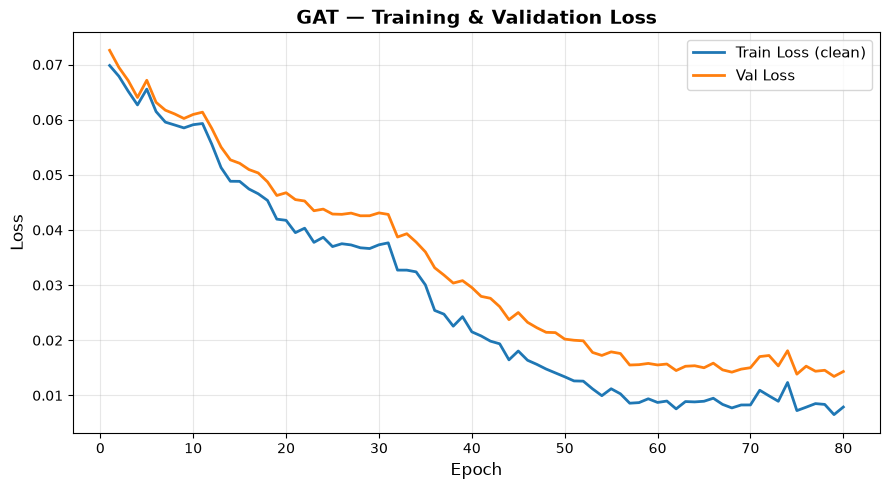

Saved: <repo>/results\Retrain_GAT\GAT_Loss_Curve.png


In [10]:
# CELL 8A  Training Loss Curve
eps = [h['ep'] for h in history]
tls = [h['tl'] for h in history]
vls = [h['vl'] for h in history]

plt.figure(figsize=(9, 5))
plt.plot(eps, tls, label='Train Loss (clean)', color='#1f77b4', linewidth=2)
plt.plot(eps, vls, label='Val Loss',           color='#ff7f0e', linewidth=2)
plt.xlabel('Epoch', fontsize=12); plt.ylabel('Loss', fontsize=12)
plt.title('GAT — Training & Validation Loss', fontsize=14, fontweight='bold')
plt.legend(fontsize=11); plt.grid(alpha=0.3); plt.tight_layout()
p = os.path.join(CONFIG['output_dir'], 'GAT_Loss_Curve.png')
plt.savefig(p, dpi=600, bbox_inches='tight'); plt.show()
print(f'Saved: {p}')


## CELL 8B — Training Accuracy Curve

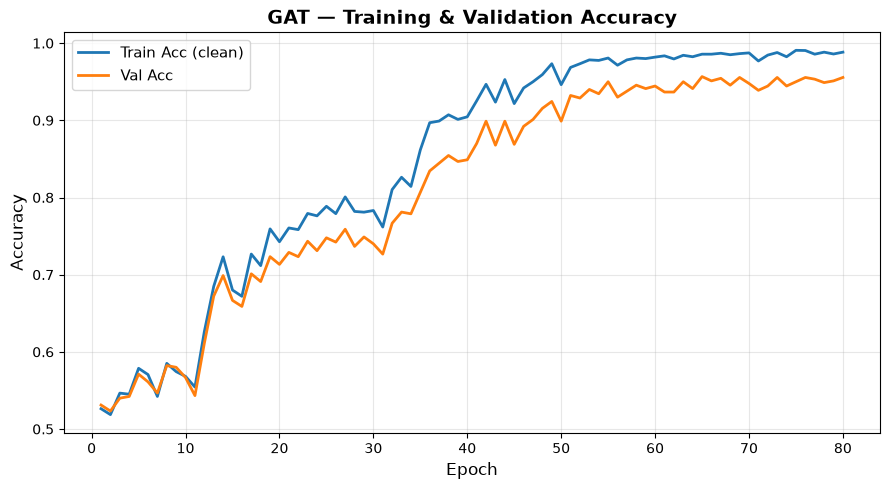

Saved: <repo>/results\Retrain_GAT\GAT_Accuracy_Curve.png


In [11]:
# CELL 8B  Training Accuracy Curve
tas = [h['ta'] for h in history]
vas = [h['va'] for h in history]

plt.figure(figsize=(9, 5))
plt.plot(eps, tas, label='Train Acc (clean)', color='#1f77b4', linewidth=2)
plt.plot(eps, vas, label='Val Acc',           color='#ff7f0e', linewidth=2)
plt.xlabel('Epoch', fontsize=12); plt.ylabel('Accuracy', fontsize=12)
plt.title('GAT — Training & Validation Accuracy', fontsize=14, fontweight='bold')
plt.legend(fontsize=11); plt.grid(alpha=0.3); plt.tight_layout()
p = os.path.join(CONFIG['output_dir'], 'GAT_Accuracy_Curve.png')
plt.savefig(p, dpi=600, bbox_inches='tight'); plt.show()
print(f'Saved: {p}')


## CELL 8C — Validation AUC-ROC Curve

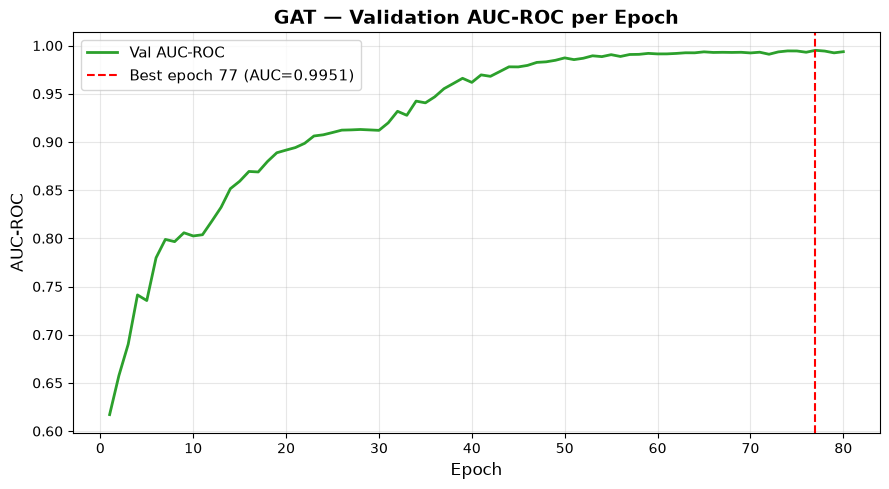

Saved: <repo>/results\Retrain_GAT\GAT_Validation_AUC_Curve.png


In [12]:
# CELL 8C  Validation AUC Curve
vaucs   = [h['vauc'] for h in history]
best_ep = eps[int(np.argmax(vaucs))]

plt.figure(figsize=(9, 5))
plt.plot(eps, vaucs, color='#2ca02c', linewidth=2, label='Val AUC-ROC')
plt.axvline(best_ep, color='red', linestyle='--', linewidth=1.5,
            label=f'Best epoch {best_ep} (AUC={max(vaucs):.4f})')
plt.xlabel('Epoch', fontsize=12); plt.ylabel('AUC-ROC', fontsize=12)
plt.title('GAT — Validation AUC-ROC per Epoch', fontsize=14, fontweight='bold')
plt.legend(fontsize=11); plt.grid(alpha=0.3); plt.tight_layout()
p = os.path.join(CONFIG['output_dir'], 'GAT_Validation_AUC_Curve.png')
plt.savefig(p, dpi=600, bbox_inches='tight'); plt.show()
print(f'Saved: {p}')


## CELL 8D — Confusion Matrix

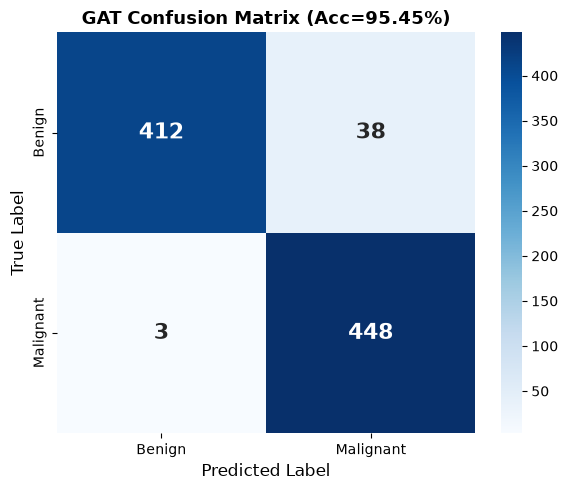

Saved: <repo>/results\Retrain_GAT\GAT_Confusion_Matrix.png


In [13]:
# CELL 8D  Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Benign', 'Malignant'],
            yticklabels=['Benign', 'Malignant'],
            cbar=True, annot_kws={'size': 16, 'weight': 'bold'})
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label',      fontsize=12)
plt.title(f'GAT Confusion Matrix (Acc={acc*100:.2f}%)',
          fontsize=13, fontweight='bold')
plt.tight_layout()
p = os.path.join(CONFIG['output_dir'], 'GAT_Confusion_Matrix.png')
plt.savefig(p, dpi=600, bbox_inches='tight'); plt.show()
print(f'Saved: {p}')


## CELL 8E — ROC Curve

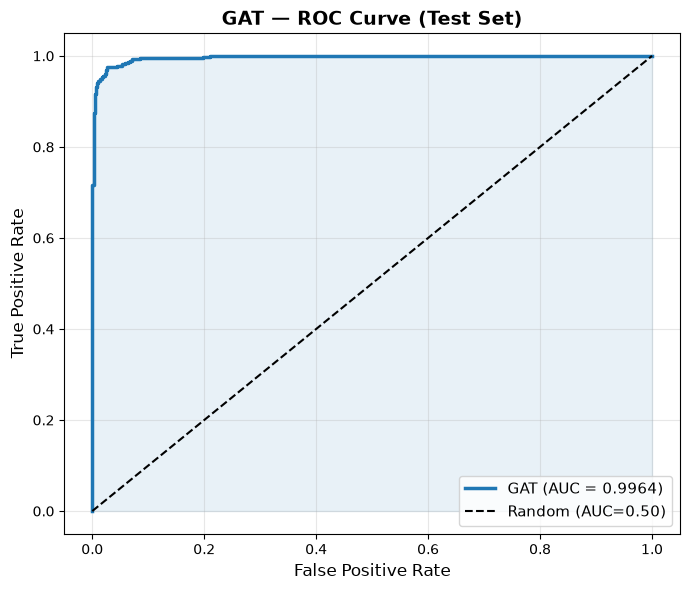

Saved: <repo>/results\Retrain_GAT\GAT_ROC_Curve.png


In [14]:
# CELL 8E  ROC Curve
plt.figure(figsize=(7, 6))
plt.plot(gat_fpr_saved, gat_tpr_saved, color='#1f77b4', linewidth=2.5,
         label=f'GAT (AUC = {gat_auc_saved:.4f})')
plt.fill_between(gat_fpr_saved, gat_tpr_saved, alpha=0.1, color='#1f77b4')
plt.plot([0,1],[0,1],'k--', linewidth=1.5, label='Random (AUC=0.50)')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate',  fontsize=12)
plt.title('GAT — ROC Curve (Test Set)', fontsize=14, fontweight='bold')
plt.legend(fontsize=11, loc='lower right')
plt.grid(alpha=0.3); plt.tight_layout()
p = os.path.join(CONFIG['output_dir'], 'GAT_ROC_Curve.png')
plt.savefig(p, dpi=600, bbox_inches='tight'); plt.show()
print(f'Saved: {p}')


## CELL 8F — Precision-Recall Curve

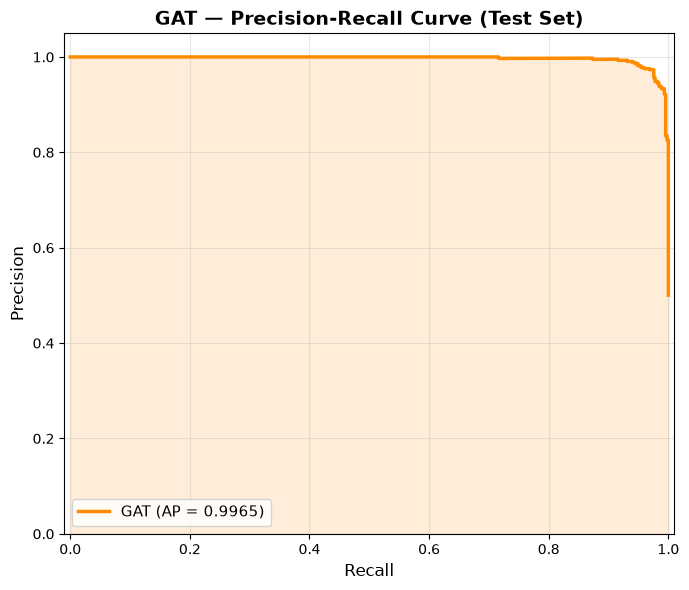

Saved: <repo>/results\Retrain_GAT\GAT_PR_Curve.png


In [15]:
# CELL 8F  Precision-Recall Curve
precision_arr, recall_arr, _ = precision_recall_curve(all_labels_test, all_probs_test)
avg_precision = average_precision_score(all_labels_test, all_probs_test)

plt.figure(figsize=(7, 6))
plt.plot(recall_arr, precision_arr, color='darkorange', linewidth=2.5,
         label=f'GAT (AP = {avg_precision:.4f})')
plt.fill_between(recall_arr, precision_arr, alpha=0.15, color='darkorange')
plt.xlabel('Recall', fontsize=12); plt.ylabel('Precision', fontsize=12)
plt.title('GAT — Precision-Recall Curve (Test Set)', fontsize=14, fontweight='bold')
plt.legend(fontsize=11, loc='lower left')
plt.grid(alpha=0.3); plt.xlim([-0.01,1.01]); plt.ylim([0,1.05])
plt.tight_layout()
p = os.path.join(CONFIG['output_dir'], 'GAT_PR_Curve.png')
plt.savefig(p, dpi=600, bbox_inches='tight'); plt.show()
print(f'Saved: {p}')


## CELL 8G — Sample Inference

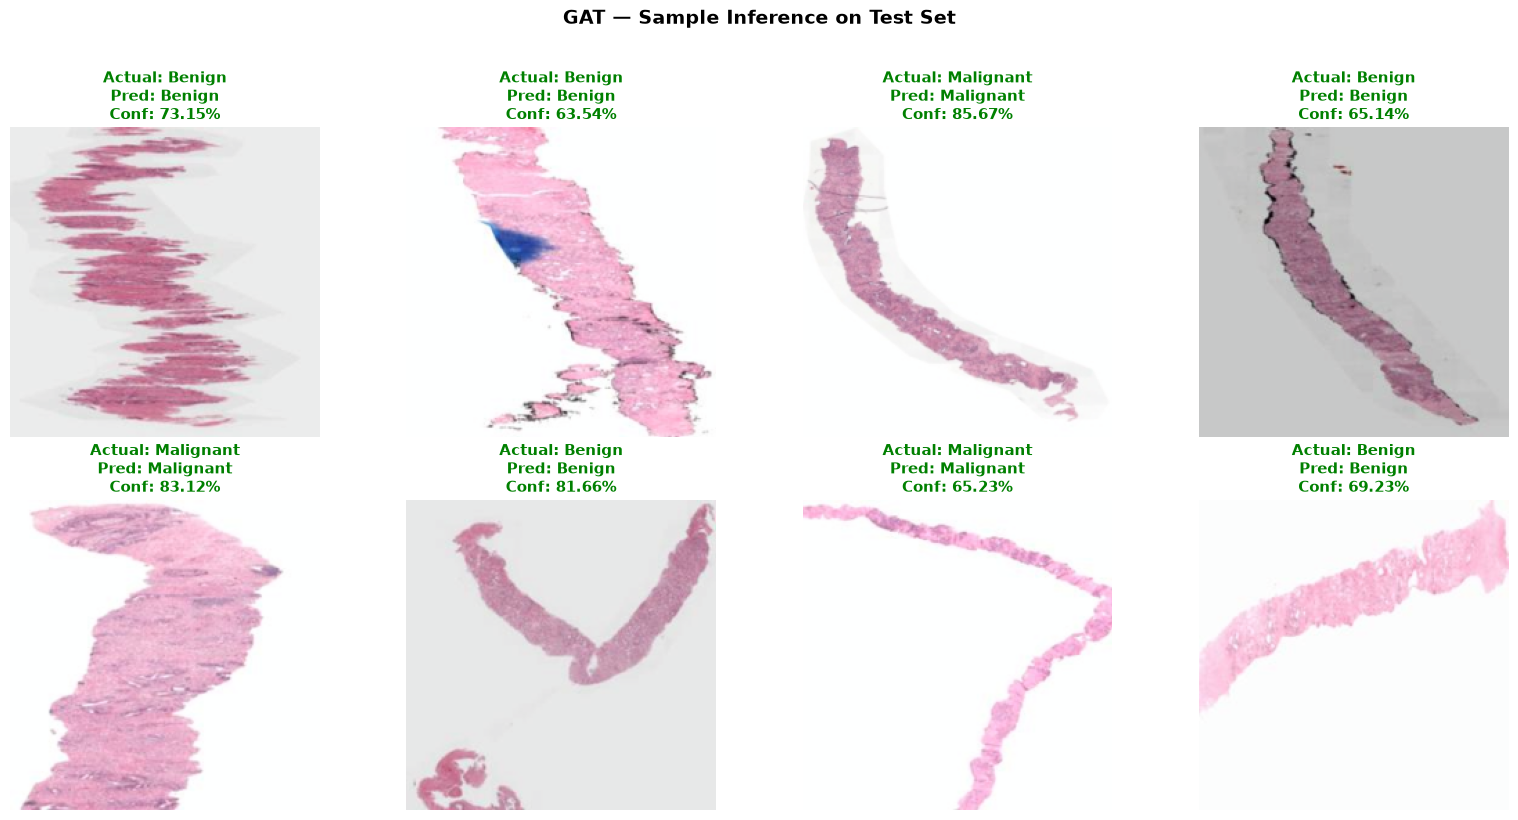

Saved: <repo>/results\Retrain_GAT\GAT_Sample_Inference.png


In [16]:
# CELL 8G Sample Inference
CLASS_NAMES = ['Benign', 'Malignant']

def predict_single(img_tensor, graph):
    model.eval()
    with torch.no_grad():
        g_batch = Batch.from_data_list([graph]).to(DEVICE)
        logits  = model(img_tensor.unsqueeze(0).to(DEVICE), g_batch)
        probs   = F.softmax(logits.float(), dim=1)[0].cpu().numpy()
    return int(np.argmax(probs)), float(probs[np.argmax(probs)])

np.random.seed(42)
sample_indices = np.random.choice(len(test_ds), 8, replace=False)

plt.figure(figsize=(16, 8))
for i, idx in enumerate(sample_indices):
    img_t, graph, label = test_ds[idx]
    pred_idx, confidence = predict_single(img_t, graph)
    is_correct = (pred_idx == int(label))
    ax = plt.subplot(2, 4, i + 1)
    ax.imshow(denormalize(img_t)); ax.axis('off')
    ax.set_title(
        f'Actual: {CLASS_NAMES[int(label)]}\n'
        f'Pred: {CLASS_NAMES[pred_idx]}\n'
        f'Conf: {confidence*100:.2f}%',
        fontsize=11, color='green' if is_correct else 'red', fontweight='bold'
    )
plt.suptitle('GAT — Sample Inference on Test Set',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
p = os.path.join(CONFIG['output_dir'], 'GAT_Sample_Inference.png')
plt.savefig(p, dpi=600, bbox_inches='tight'); plt.show()
print(f'Saved: {p}')


## CELL 8H — Sobel Edge Detection on Sample Inference Images

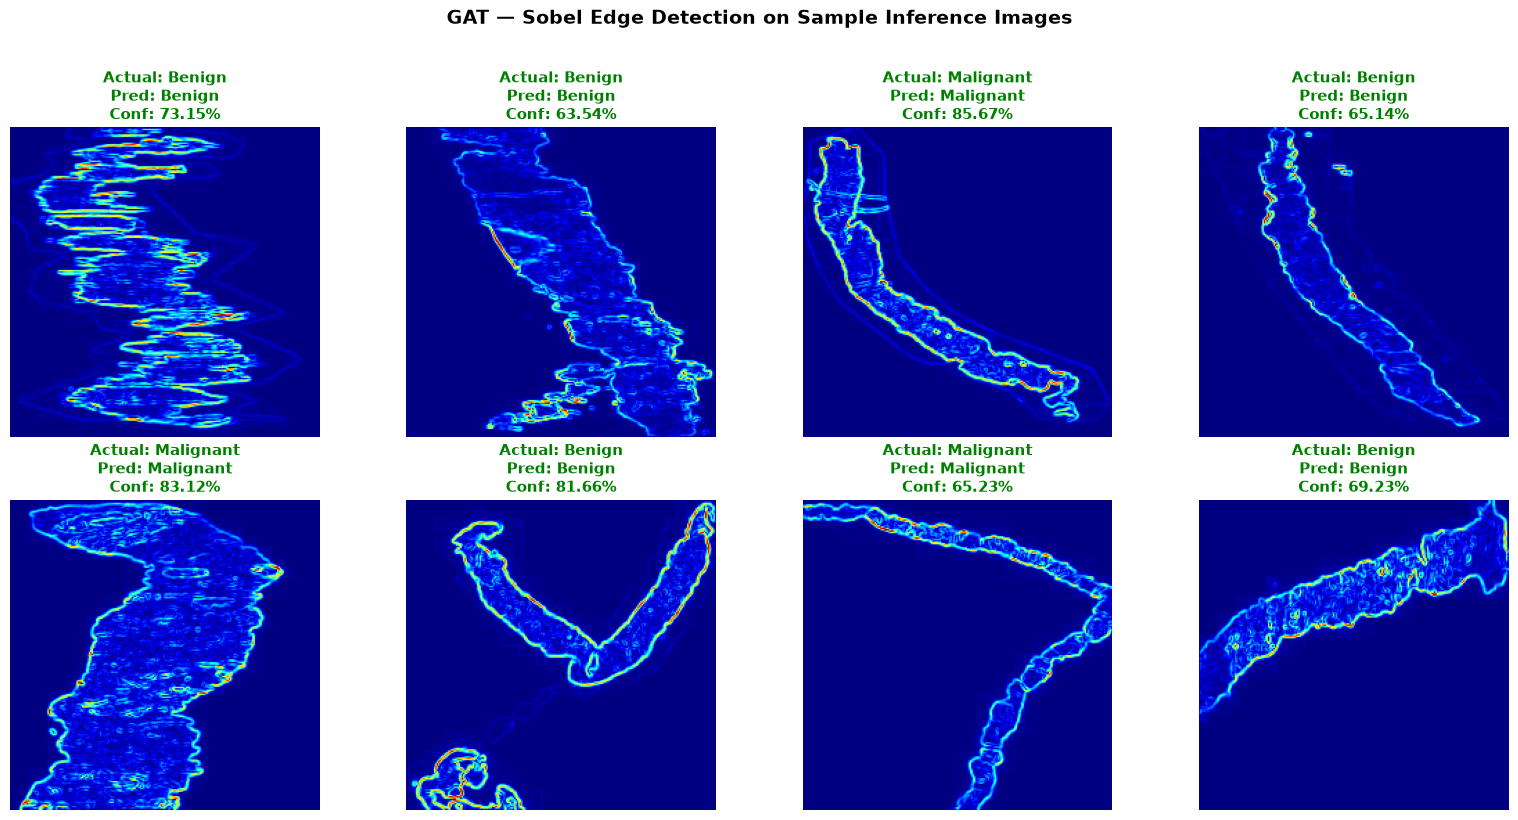

Saved: <repo>/results\Retrain_GAT\GAT_Sobel_Edge_Inference.png


In [17]:
# CELL 8H Sobel Edge Detection on Sample Inference Images (JET colormap)
plt.figure(figsize=(16, 8))
for i, idx in enumerate(sample_indices):
    img_t, graph, label = test_ds[idx]
    pred_idx, confidence = predict_single(img_t, graph)
    is_correct = (pred_idx == int(label))

    img_display = denormalize(img_t)
    img_uint8   = (img_display * 255).astype(np.uint8)
    img_gray    = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2GRAY)
    sobel_x     = cv2.Sobel(img_gray, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y     = cv2.Sobel(img_gray, cv2.CV_64F, 0, 1, ksize=3)
    magnitude   = cv2.magnitude(sobel_x, sobel_y)
    mag_norm    = cv2.normalize(magnitude, None, 0, 255, cv2.NORM_MINMAX, cv2.CV_8U)
    edges_rgb   = cv2.cvtColor(
        cv2.applyColorMap(mag_norm, cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB
    )

    ax = plt.subplot(2, 4, i + 1)
    ax.imshow(edges_rgb); ax.axis('off')
    ax.set_title(
        f'Actual: {CLASS_NAMES[int(label)]}\n'
        f'Pred: {CLASS_NAMES[pred_idx]}\n'
        f'Conf: {confidence*100:.2f}%',
        fontsize=11, color='green' if is_correct else 'red', fontweight='bold'
    )
plt.suptitle('GAT — Sobel Edge Detection on Sample Inference Images',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
p = os.path.join(CONFIG['output_dir'], 'GAT_Sobel_Edge_Inference.png')
plt.savefig(p, dpi=600, bbox_inches='tight'); plt.show()
print(f'Saved: {p}')


## CELL 8I — Canny Edge Detection on Sample Inference Images

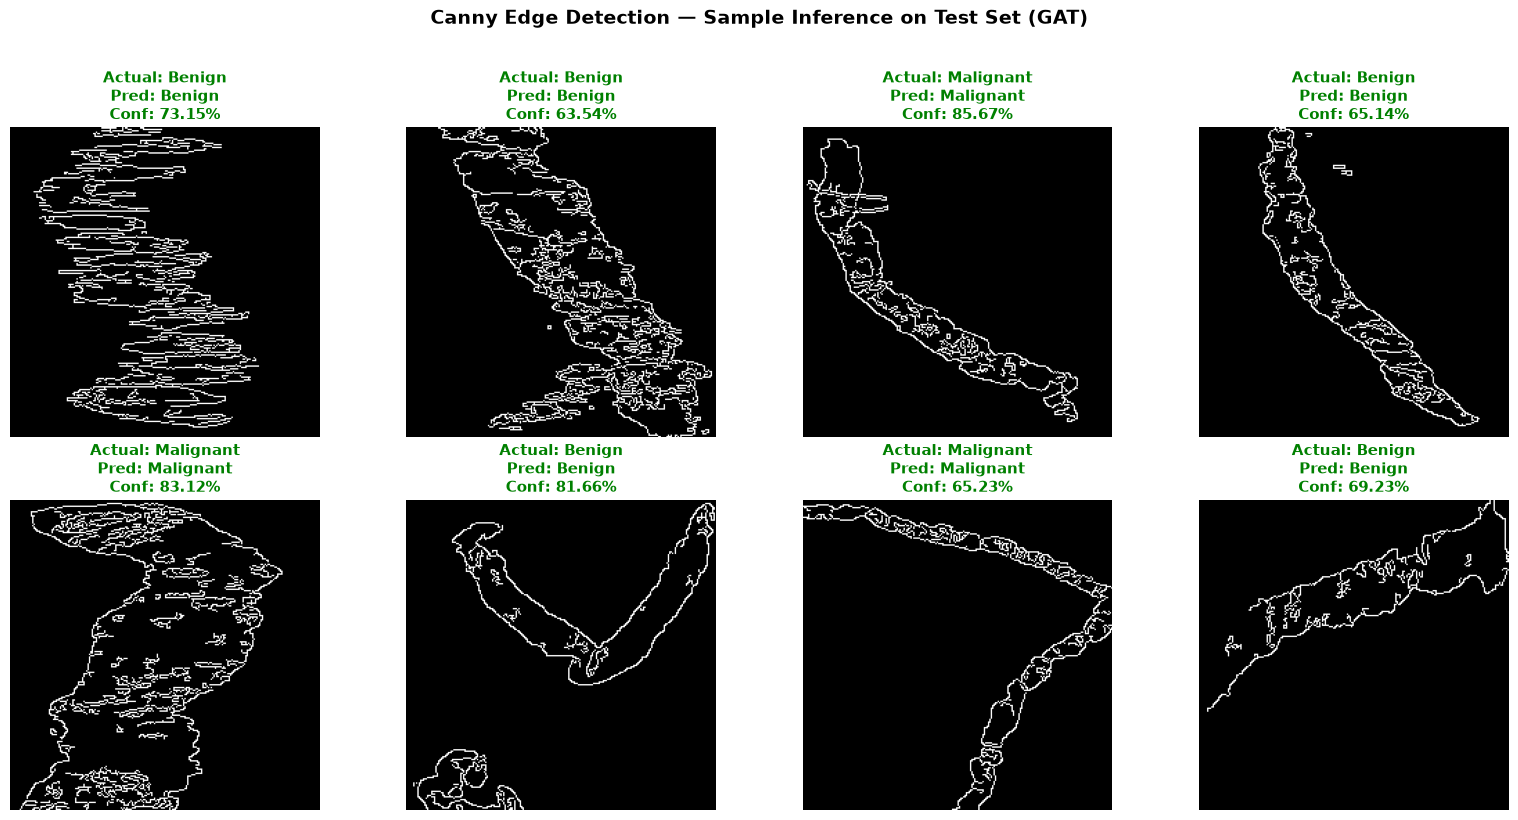


Canny edge maps for 8 random test samples
Saved to: <repo>/results\Retrain_GAT\GAT_Canny_Edge_Inference.png
Green title = correct prediction | Red title = incorrect


In [18]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 8I — Canny Edge Detection on Sample Inference Images    ║
# ║ Shows edge maps for the same 8 test samples from Cell 8G     ║
# ╚══════════════════════════════════════════════════════════════╝
import cv2
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(16, 8))

for i, idx in enumerate(sample_indices):   # reuses sample_indices from Cell 8G
    img_tensor, graph, label = test_ds[idx]

    pred_idx, confidence = predict_single(img_tensor, graph)

    actual_class    = CLASS_NAMES[int(label)]
    predicted_class = CLASS_NAMES[pred_idx]
    is_correct      = (pred_idx == int(label))

    # ── Denormalize → uint8 → grayscale → Canny ────────────
    img_display = denormalize(img_tensor)
    img_uint8   = (img_display * 255).astype(np.uint8)
    img_gray    = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2GRAY)
    edges       = cv2.Canny(img_gray, threshold1=50, threshold2=150)

    ax = plt.subplot(2, 4, i + 1)
    ax.imshow(edges, cmap='gray')
    ax.axis('off')

    title_color = 'green' if is_correct else 'red'
    ax.set_title(
        f'Actual: {actual_class}\n'
        f'Pred: {predicted_class}\n'
        f'Conf: {confidence*100:.2f}%',
        fontsize=11, color=title_color, fontweight='bold'
    )

plt.suptitle('Canny Edge Detection — Sample Inference on Test Set (GAT)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
save_p = os.path.join(CONFIG['output_dir'], 'GAT_Canny_Edge_Inference.png')
plt.savefig(save_p, dpi=600, bbox_inches='tight')
plt.show()

print(f'\nCanny edge maps for 8 random test samples')
print(f'Saved to: {save_p}')
print(f'Green title = correct prediction | Red title = incorrect')


## CELL 8J — Morphological Operations on Canny Edge Maps

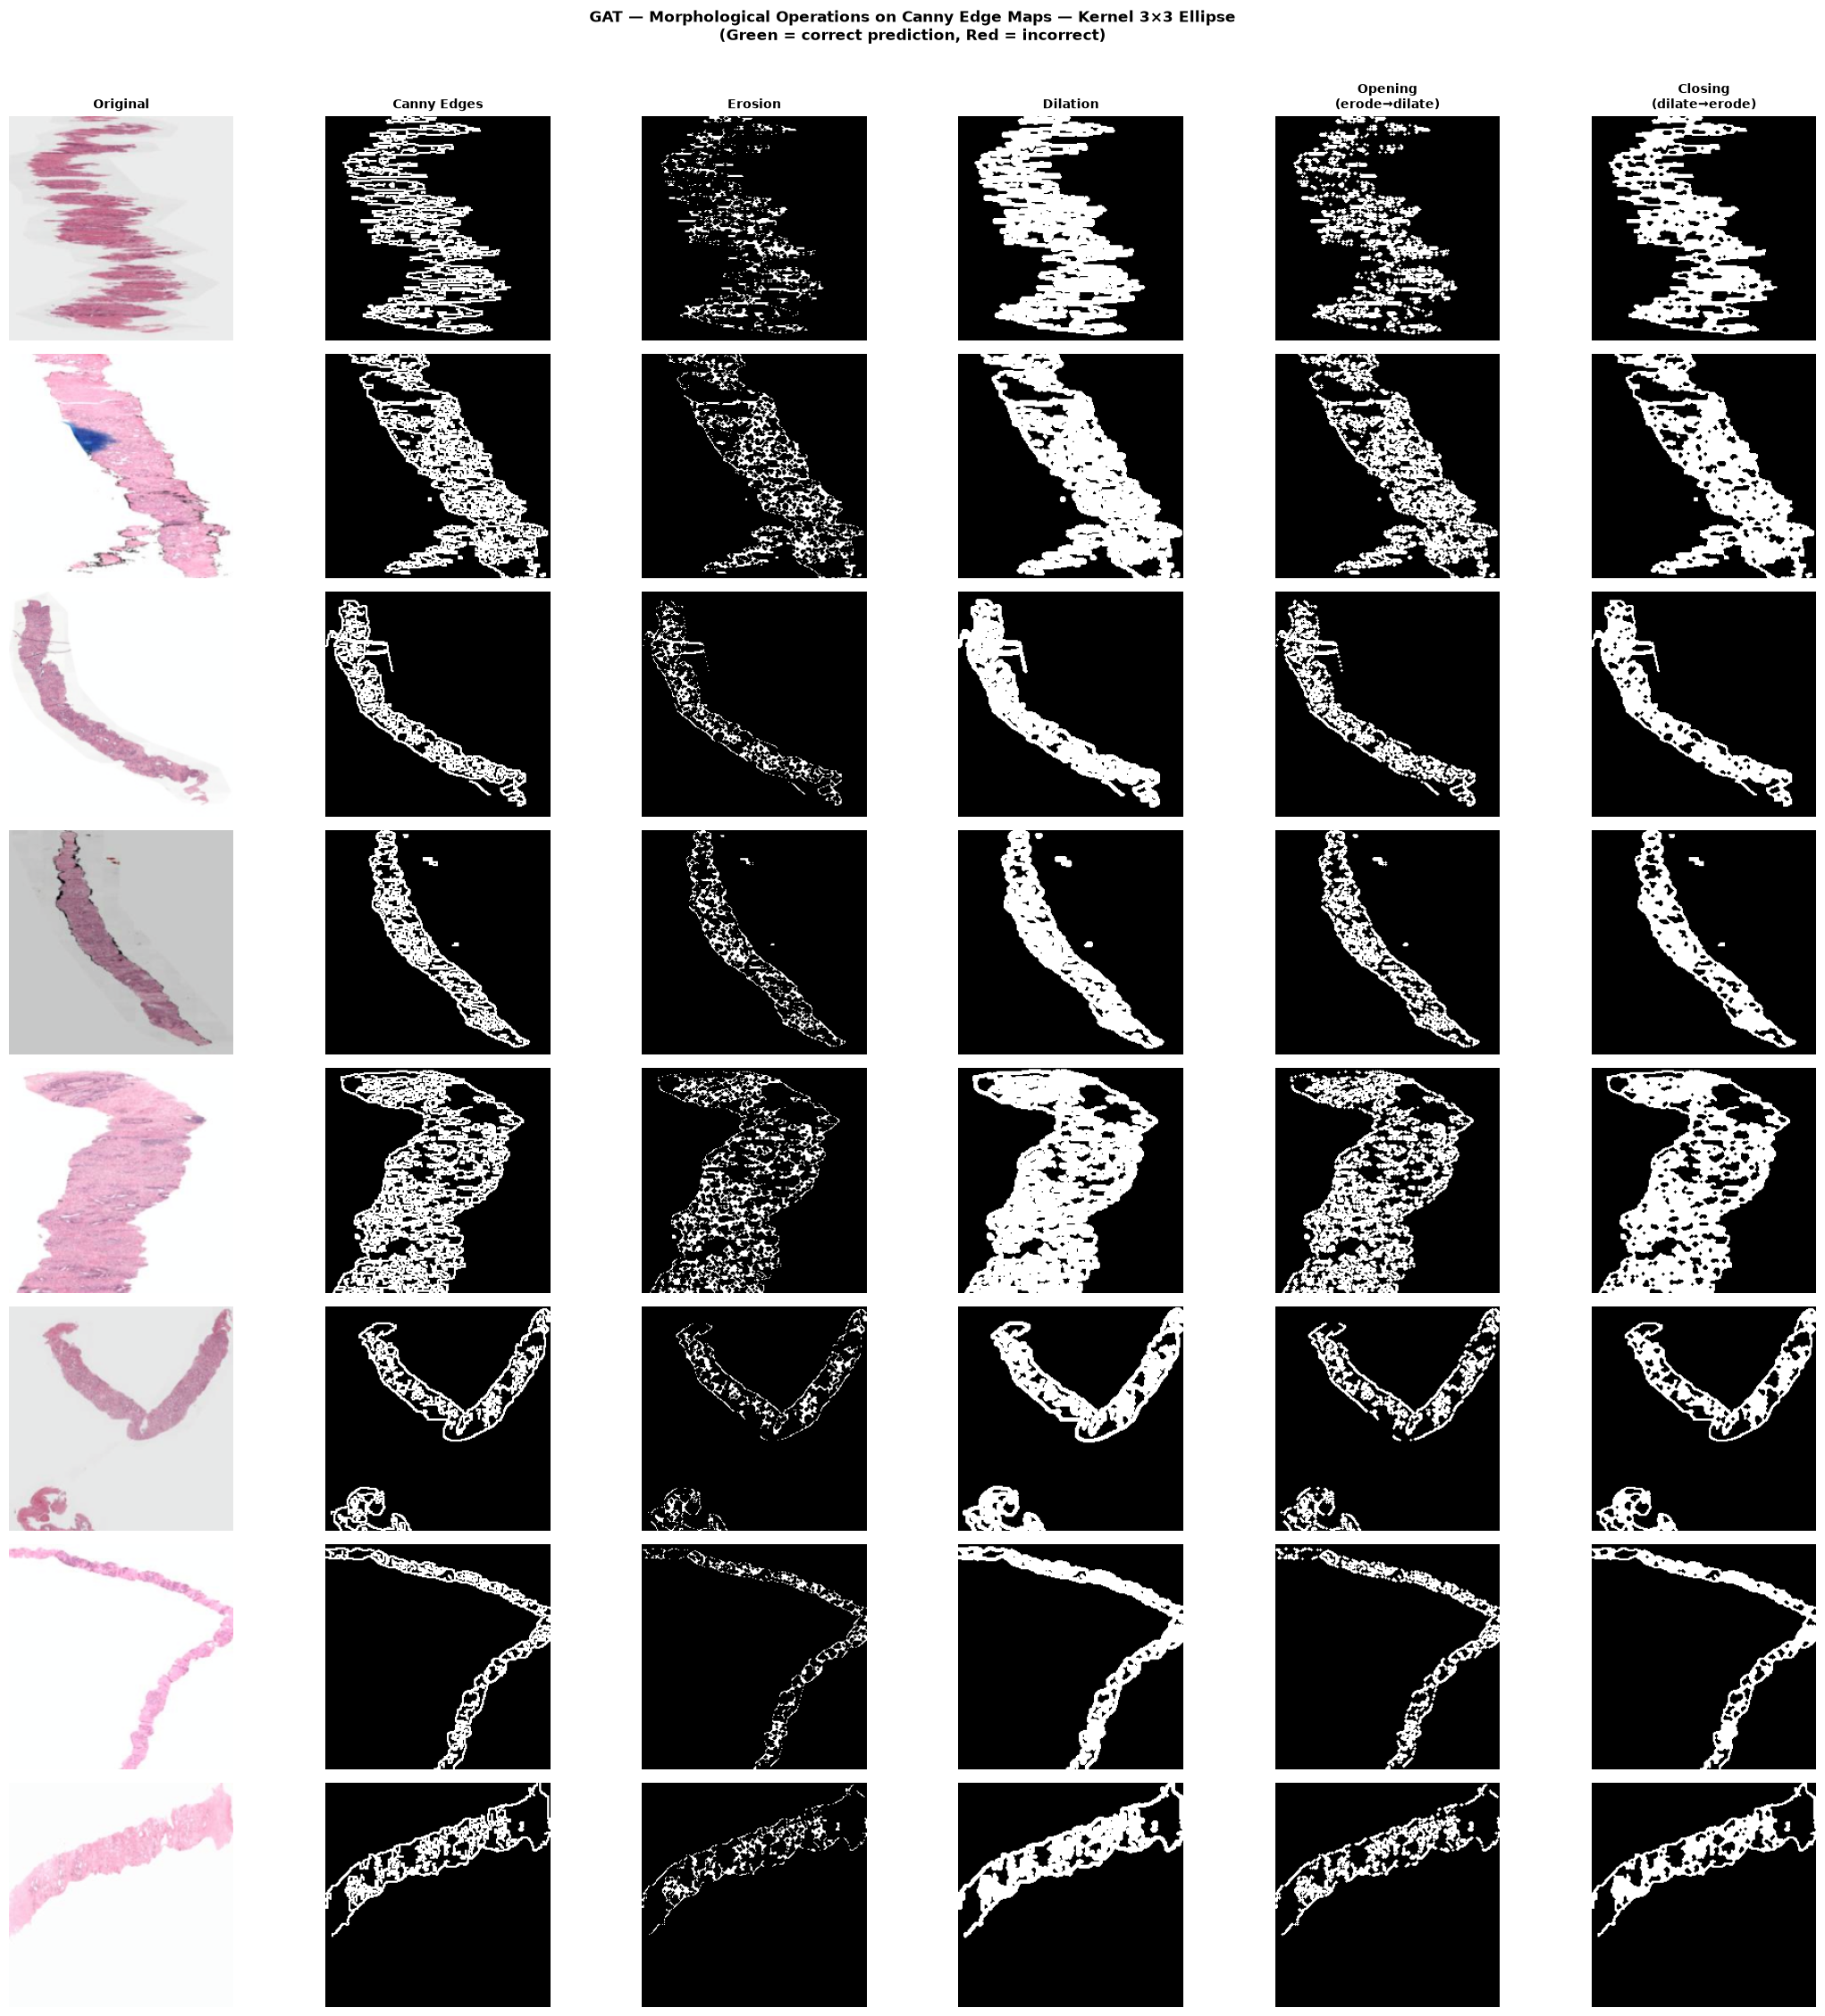

Saved to: <repo>/results\Retrain_GAT\GAT_Morphological_Canny.png


In [19]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 8J — Morphological Operations on Canny Edge Maps        ║
# ║ Pre-dilates edges to 2-3px thick before morphology so         ║
# ║ erosion produces a visible result.                            ║
# ╚══════════════════════════════════════════════════════════════╝
import cv2
import numpy as np
import matplotlib.pyplot as plt

pre_kernel = cv2.getStructuringElement(cv2.MORPH_RECT,    (2, 2))
kernel     = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))

n_show         = 8
np.random.seed(42)
sample_indices_m = np.random.choice(len(test_ds), n_show, replace=False)

fig, axes = plt.subplots(n_show, 6, figsize=(22, n_show * 2.8))
col_titles = ['Original', 'Canny Edges', 'Erosion', 'Dilation',
              'Opening\n(erode→dilate)', 'Closing\n(dilate→erode)']

for col, title in enumerate(col_titles):
    axes[0, col].set_title(title, fontsize=10, fontweight='bold')

for row, idx in enumerate(sample_indices_m):
    img_tensor, graph, label = test_ds[idx]
    pred_idx, confidence     = predict_single(img_tensor, graph)

    actual_class    = CLASS_NAMES[int(label)]
    predicted_class = CLASS_NAMES[pred_idx]
    is_correct      = (pred_idx == int(label))
    color           = 'green' if is_correct else 'red'

    img_display = denormalize(img_tensor)
    img_uint8   = (img_display * 255).astype(np.uint8)
    img_gray    = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2GRAY)

    edges = cv2.Canny(img_gray, threshold1=30, threshold2=100)
    edges = cv2.dilate(edges, pre_kernel, iterations=1)

    eroded  = cv2.erode(edges,  kernel, iterations=1)
    dilated = cv2.dilate(edges, kernel, iterations=1)
    opened  = cv2.morphologyEx(edges, cv2.MORPH_OPEN,  kernel)
    closed  = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel)

    for col, (img, cmap) in enumerate([
        (img_display, None  ),
        (edges,       'gray'),
        (eroded,      'gray'),
        (dilated,     'gray'),
        (opened,      'gray'),
        (closed,      'gray'),
    ]):
        ax = axes[row, col]
        ax.imshow(img, cmap=cmap)
        ax.axis('off')
        if col == 0:
            ax.set_ylabel(
                f'A:{actual_class}\nP:{predicted_class}\n{confidence*100:.1f}%',
                fontsize=7, color=color, rotation=0,
                labelpad=85, va='center'
            )

plt.suptitle(
    'GAT — Morphological Operations on Canny Edge Maps — Kernel 3×3 Ellipse\n'
    '(Green = correct prediction, Red = incorrect)',
    fontsize=12, fontweight='bold', y=1.005
)
plt.tight_layout()
save_p = os.path.join(CONFIG['output_dir'], 'GAT_Morphological_Canny.png')
plt.savefig(save_p, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved to: {save_p}')


## CELL 8K — Morphological Operations on Sobel Edge Maps

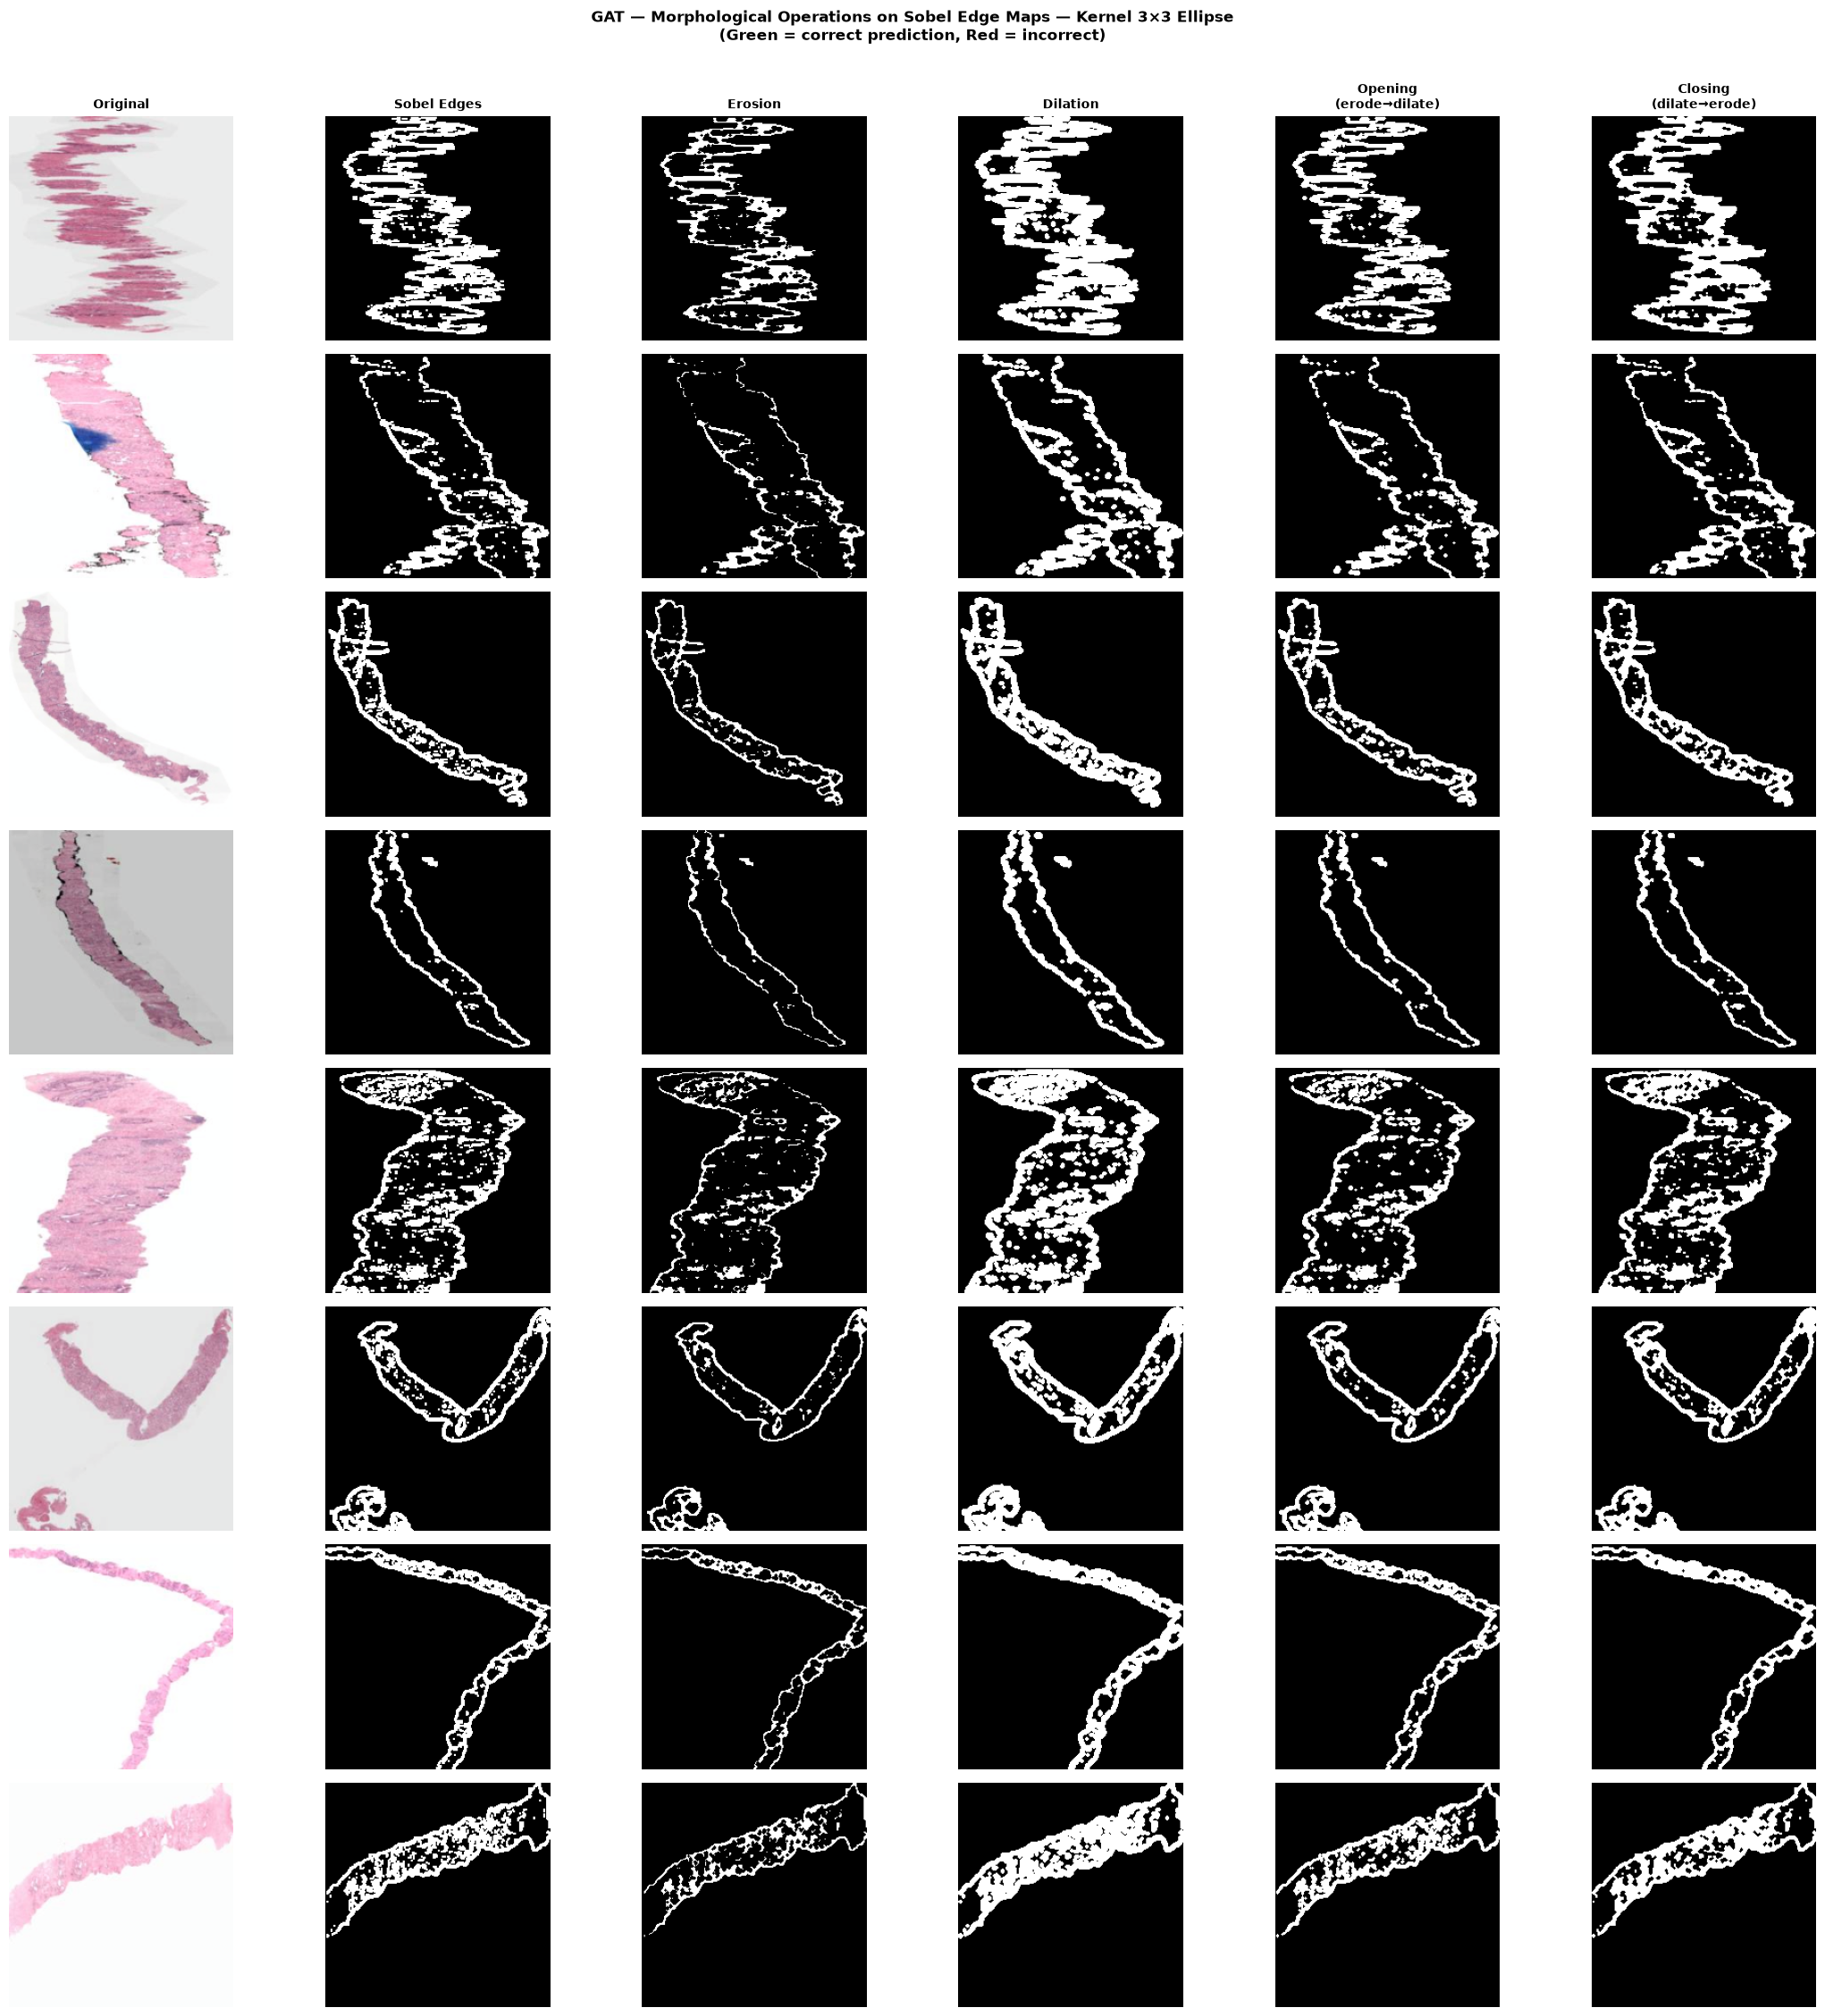

Saved to: <repo>/results\Retrain_GAT\GAT_Morphological_Sobel.png


In [20]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 8K — Morphological Operations on Sobel Edge Maps        ║
# ╚══════════════════════════════════════════════════════════════╝
import cv2
import numpy as np
import matplotlib.pyplot as plt

pre_kernel = cv2.getStructuringElement(cv2.MORPH_RECT,    (2, 2))
kernel     = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))

n_show         = 8
np.random.seed(42)
sample_indices_ms = np.random.choice(len(test_ds), n_show, replace=False)

fig, axes = plt.subplots(n_show, 6, figsize=(22, n_show * 2.8))
col_titles = ['Original', 'Sobel Edges', 'Erosion', 'Dilation',
              'Opening\n(erode→dilate)', 'Closing\n(dilate→erode)']

for col, title in enumerate(col_titles):
    axes[0, col].set_title(title, fontsize=10, fontweight='bold')

for row, idx in enumerate(sample_indices_ms):
    img_tensor, graph, label = test_ds[idx]
    pred_idx, confidence     = predict_single(img_tensor, graph)

    actual_class    = CLASS_NAMES[int(label)]
    predicted_class = CLASS_NAMES[pred_idx]
    is_correct      = (pred_idx == int(label))
    color           = 'green' if is_correct else 'red'

    img_display = denormalize(img_tensor)
    img_uint8   = (img_display * 255).astype(np.uint8)
    img_gray    = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2GRAY)

    sobel_x   = cv2.Sobel(img_gray, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y   = cv2.Sobel(img_gray, cv2.CV_64F, 0, 1, ksize=3)
    magnitude = cv2.magnitude(sobel_x, sobel_y)
    mag_norm  = cv2.normalize(magnitude, None, 0, 255,
                              cv2.NORM_MINMAX, cv2.CV_8U)

    _, edges = cv2.threshold(mag_norm, 50, 255, cv2.THRESH_BINARY)
    edges    = cv2.dilate(edges, pre_kernel, iterations=1)

    eroded  = cv2.erode(edges,  kernel, iterations=1)
    dilated = cv2.dilate(edges, kernel, iterations=1)
    opened  = cv2.morphologyEx(edges, cv2.MORPH_OPEN,  kernel)
    closed  = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel)

    for col, (img, cmap) in enumerate([
        (img_display, None  ),
        (edges,       'gray'),
        (eroded,      'gray'),
        (dilated,     'gray'),
        (opened,      'gray'),
        (closed,      'gray'),
    ]):
        ax = axes[row, col]
        ax.imshow(img, cmap=cmap)
        ax.axis('off')
        if col == 0:
            ax.set_ylabel(
                f'A:{actual_class}\nP:{predicted_class}\n{confidence*100:.1f}%',
                fontsize=7, color=color, rotation=0,
                labelpad=85, va='center'
            )

plt.suptitle(
    'GAT — Morphological Operations on Sobel Edge Maps — Kernel 3×3 Ellipse\n'
    '(Green = correct prediction, Red = incorrect)',
    fontsize=12, fontweight='bold', y=1.005
)
plt.tight_layout()
save_p = os.path.join(CONFIG['output_dir'], 'GAT_Morphological_Sobel.png')
plt.savefig(save_p, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved to: {save_p}')


## CELL 8L — Final Performance Summary

In [21]:
# CELL 8I — Final Performance Summary
print('═' * 60)
print('CLASSIFICATION REPORT — Test Set')
print('═' * 60)
print(classification_report(all_labels_test, all_preds_test,
                            target_names=['Benign', 'Malignant'], digits=4))
print('═' * 60)
print(f'Accuracy    :  {acc:.4f}  ({acc*100:.2f}%)')
print(f'AUC-ROC     :  {auc_sc:.4f}')
print(f'F1 Score    :  {f1:.4f}')
print(f'Precision   :  {prec:.4f}')
print(f'Recall      :  {rec:.4f}')
print(f'MCC         :  {mcc:.4f}')
print(f'Sensitivity :  {sensitivity:.4f}')
print(f'Specificity :  {specificity:.4f}')
print('═' * 60)
print()
print('Architecture summary:')
print(f'  Graph type   : k-NN spatial (k={CONFIG["k_neighbors"]}) — same as LGCN')
print(f'  GAT layers   : {CONFIG["gat_layers"]} × {CONFIG["gat_heads"]} heads')
print(f'  GAT hidden   : {CONFIG["gat_hidden_dim"]} per head')
print(f'  GAT out      : {model.gat.out_dim}-dim (after mean+max pool proj)')
print(f'  Fusion       : CNN({CONFIG["fusion_dim"]}) + GAT({model.gat.out_dim}) = {CONFIG["fusion_dim"]+model.gat.out_dim}-dim')
print(f'  CNN freeze   : blocks 0-4 (same as LGCN)')
print()
print('Why lower than Hybrid:')
print('  Hybrid uses GAT + GCN dual branch + SE-gated fusion (896-dim)')
print('  This model is GAT standalone — no GCN structural signal,')
print('  no SE gate to balance branches → less complementary information')
print()
print('All plots saved as PNG (600 DPI) in:', CONFIG['output_dir'])
print('  GAT_Loss_Curve.png')
print('  GAT_Accuracy_Curve.png')
print('  GAT_Validation_AUC_Curve.png')
print('  GAT_Confusion_Matrix.png')
print('  GAT_ROC_Curve.png')
print('  GAT_PR_Curve.png')
print('  GAT_Sample_Inference.png')
print('  GAT_Sobel_Edge_Inference.png')


════════════════════════════════════════════════════════════
CLASSIFICATION REPORT — Test Set
════════════════════════════════════════════════════════════
              precision    recall  f1-score   support

      Benign     0.9928    0.9156    0.9526       450
   Malignant     0.9218    0.9933    0.9562       451

    accuracy                         0.9545       901
   macro avg     0.9573    0.9545    0.9544       901
weighted avg     0.9573    0.9545    0.9544       901

════════════════════════════════════════════════════════════
Accuracy    :  0.9545  (95.45%)
AUC-ROC     :  0.9964
F1 Score    :  0.9544
Precision   :  0.9573
Recall      :  0.9545
MCC         :  0.9117
Sensitivity :  0.9933
Specificity :  0.9156
════════════════════════════════════════════════════════════

Architecture summary:
  Graph type   : k-NN spatial (k=6) — same as LGCN
  GAT layers   : 3 × 2 heads
  GAT hidden   : 256 per head
  GAT out      : 256-dim (after mean+max pool proj)
  Fusion       : CNN(512)